# 第 12 章 配套验证代码：省电到底怎么算（Horowitz 2014、盈亏线、访存墙与 QNN-SNN Twin）

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Casey-sketch-cyber/gnn2gsnn/blob/main/notion/notebooks/ch12_energy_and_quantization.ipynb)

本 Notebook 仅使用 `numpy` 与 `matplotlib`，逐项验证第 12 章（对应验收标准第 6 条）的全部能耗推导与手算数值：
1. **Horowitz (ISSCC 2014, p. 14 Fig. 1.1.9)** 原始 45nm 0.9V 运算与访存能耗表及 `4.6 pJ / 0.9 pJ` 来源
2. 不同精度下的纯计算盈亏线：FP32（`5.11`）、INT8 对比 FP32 AC（`0.256`）、INT8 权重 + INT32 累加器（`3.00`）与计入 ReLU 稀疏度 $\gamma$ 后的收缩
3. **例 12.1（验收标准第 6 条核心手算）**：3 层网络（`64 -> 128 -> 64 -> 10`）给定各层脉冲数与扇出，逐步计算 SynOps，并与 FP32 ANN、INT8 ANN 及计入 8KB SRAM 权重/膜电位访存后的总能耗对比
4. **Yan 等（IEEE TCAD 2026, `arXiv:2409.08290v6`）QNN-SNN Twin 解析模型**复现：等价位宽 $b=\lceil\log_2(T+1)\rceil$、稀疏度区间、22nm 典型类脑芯片上的发放率盈亏曲线与稀疏路由/稠密广播交叉点

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

def setup_plot_font():
    """配置中文字体；若当前环境缺少中文字体，则自动回退英文标签避免方框。"""
    candidates = [
        'SimHei', 'Microsoft YaHei', 'PingFang SC',
        'Noto Sans CJK SC', 'WenQuanYi Micro Hei', 'Source Han Sans SC'
    ]
    available = {f.name for f in fm.fontManager.ttflist}
    for name in candidates:
        if name in available:
            plt.rcParams['font.sans-serif'] = [name, 'DejaVu Sans']
            plt.rcParams['axes.unicode_minus'] = False
            return True
    plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
    plt.rcParams['axes.unicode_minus'] = False
    return False

USE_ZH = setup_plot_font()
np.set_printoptions(precision=4, suppress=True)
print(f"Font setup done. USE_ZH = {USE_ZH}")


Font setup done. USE_ZH = True


## 1. Horowitz (2014) 45nm 0.9V 原始数据与各精度纯计算盈亏线

In [2]:
# Horowitz (ISSCC 2014, p. 14, Fig. 1.1.9) 45nm CMOS 0.9V 原始数据 (单位: pJ)
H = {
    'int8_add': 0.03,
    'int32_add': 0.1,
    'fp16_add': 0.4,
    'fp32_add': 0.9,
    'int8_mult': 0.2,
    'int32_mult': 3.1,
    'fp16_mult': 1.1,
    'fp32_mult': 3.7,
    'sram_8kb_64b': 10.0,
    'sram_32kb_64b': 20.0,
    'sram_1mb_64b': 100.0,
    'dram_64b_low': 1300.0,
    'dram_64b_high': 2600.0,
}

E_MAC_FP32 = H['fp32_mult'] + H['fp32_add']       # 3.7 + 0.9 = 4.6 pJ
E_AC_FP32  = H['fp32_add']                         # 0.9 pJ
E_MAC_INT8_8ACC  = H['int8_mult'] + H['int8_add']  # 0.2 + 0.03 = 0.23 pJ
E_MAC_INT8_32ACC = H['int8_mult'] + H['int32_add'] # 0.2 + 0.1 = 0.30 pJ
E_AC_INT32 = H['int32_add']                        # 0.1 pJ
E_AC_INT8  = H['int8_add']                         # 0.03 pJ

assert np.isclose(E_MAC_FP32, 4.6)
assert np.isclose(E_AC_FP32, 0.9)
assert np.isclose(E_MAC_INT8_8ACC, 0.23)
assert np.isclose(E_MAC_INT8_32ACC, 0.30)

# 纯计算盈亏线 rho* = r * T = (1 - gamma) * E_MAC / E_AC
scenarios = [
    ("FP32 ANN vs FP32 SNN (gamma=0)",          E_MAC_FP32,       E_AC_FP32,  0.0),
    ("INT8(8b acc) ANN vs FP32 SNN (gamma=0)",  E_MAC_INT8_8ACC,  E_AC_FP32,  0.0),
    ("INT8(32b acc) ANN vs FP32 SNN (gamma=0)", E_MAC_INT8_32ACC, E_AC_FP32,  0.0),
    ("INT8(32b acc) ANN vs INT32-acc SNN (gamma=0)",   E_MAC_INT8_32ACC, E_AC_INT32, 0.0),
    ("INT8(32b acc) ANN vs INT32-acc SNN (gamma=0.5)", E_MAC_INT8_32ACC, E_AC_INT32, 0.5),
    ("INT8(32b acc) ANN vs INT32-acc SNN (gamma=0.8)", E_MAC_INT8_32ACC, E_AC_INT32, 0.8),
    ("INT8(8b acc) ANN vs INT8-acc SNN (gamma=0)",     E_MAC_INT8_8ACC,  E_AC_INT8,  0.0),
]
print(f"{'对比场景':<48} | E_MAC  | E_AC  | 盈亏上限 rho* = r*T")
print("-" * 82)
for name, em, ea, gam in scenarios:
    rho_star = (1.0 - gam) * em / ea
    print(f"{name:<48} | {em:6.2f} | {ea:5.2f} | {rho_star:6.3f}")

assert np.isclose(E_MAC_FP32 / E_AC_FP32, 4.6 / 0.9)
assert np.isclose(E_MAC_INT8_8ACC / E_AC_FP32, 0.23 / 0.9)
assert np.isclose(E_MAC_INT8_32ACC / E_AC_INT32, 3.0)
print("[PASS] Horowitz 2014 原始组合值与各精度纯计算盈亏线验证通过！")


对比场景                                             | E_MAC  | E_AC  | 盈亏上限 rho* = r*T
----------------------------------------------------------------------------------
FP32 ANN vs FP32 SNN (gamma=0)                   |   4.60 |  0.90 |  5.111
INT8(8b acc) ANN vs FP32 SNN (gamma=0)           |   0.23 |  0.90 |  0.256
INT8(32b acc) ANN vs FP32 SNN (gamma=0)          |   0.30 |  0.90 |  0.333
INT8(32b acc) ANN vs INT32-acc SNN (gamma=0)     |   0.30 |  0.10 |  3.000
INT8(32b acc) ANN vs INT32-acc SNN (gamma=0.5)   |   0.30 |  0.10 |  1.500
INT8(32b acc) ANN vs INT32-acc SNN (gamma=0.8)   |   0.30 |  0.10 |  0.600
INT8(8b acc) ANN vs INT8-acc SNN (gamma=0)       |   0.23 |  0.03 |  7.667
[PASS] Horowitz 2014 原始组合值与各精度纯计算盈亏线验证通过！


## 2. 例 12.1（验收标准第 6 条核心手算）：3 层网络能耗估算与访存墙对比

In [3]:
# 3 层全连接网络: 64 -> 128 -> 64 -> 10，时间步 T = 8
dims = [(64, 128), (128, 64), (64, 10)]
# 给定每层输入侧在 T=8 步内总共发出的脉冲数 S^(l-1)
spikes_in = [96, 160, 64]
T_steps = 8

macs_per_layer = [d_in * d_out for d_in, d_out in dims]
fanouts = [d_out for _, d_out in dims]
synops_per_layer = [s * fo for s, fo in zip(spikes_in, fanouts)]
rho_per_layer = [syn / mac for syn, mac in zip(synops_per_layer, macs_per_layer)]
rate_per_layer = [rho / T_steps for rho in rho_per_layer]

total_macs = sum(macs_per_layer)
total_synops = sum(synops_per_layer)
avg_rho = total_synops / total_macs

print("层  | 形状       | 扇出 | ANN MACs | 总脉冲 S | SNN SynOps | 每突触事件 rho | 发放率 r")
print("-" * 86)
for l, ((di, do), mac, s, syn, rho, r) in enumerate(
    zip(dims, macs_per_layer, spikes_in, synops_per_layer, rho_per_layer, rate_per_layer), 1
):
    print(f"L{l}  | {di:3d} -> {do:3d} | {do:4d} | {mac:8d} | {s:8d} | {syn:10d} | {rho:14.3f} | {r:7.4f}")
print("-" * 86)
print(f"合计 | —          | —    | {total_macs:8d} | {sum(spikes_in):8d} | {total_synops:10d} | {avg_rho:14.3f} | {avg_rho/T_steps:7.4f}")

assert total_macs == 17024
assert synops_per_layer == [12288, 10240, 640]
assert total_synops == 23168

# 1) 纯计算能耗比较 (pJ)
E_ann_fp32_comp = total_macs * E_MAC_FP32          # 78,310.4 pJ
E_snn_fp32_comp = total_synops * E_AC_FP32         # 20,851.2 pJ
E_ann_int8_32_comp = total_macs * E_MAC_INT8_32ACC # 5,107.2 pJ
E_ann_int8_8_comp  = total_macs * E_MAC_INT8_8ACC  # 3,915.52 pJ
E_snn_int32_comp   = total_synops * E_AC_INT32     # 2,316.8 pJ

print("\n=== 纯计算能耗（单位: pJ）===")
print(f"FP32 ANN (4.6 pJ/MAC):          {E_ann_fp32_comp:10.2f} pJ")
print(f"FP32 SNN (0.9 pJ/AC):           {E_snn_fp32_comp:10.2f} pJ  (相对 FP32 ANN 省电 {E_ann_fp32_comp/E_snn_fp32_comp:.2f}x)")
print(f"INT8 ANN (0.30 pJ, 32b acc):    {E_ann_int8_32_comp:10.2f} pJ  (FP32 SNN 反而更费电 {E_snn_fp32_comp/E_ann_int8_32_comp:.2f}x!)")
print(f"INT8 ANN (0.23 pJ, 8b acc):     {E_ann_int8_8_comp:10.2f} pJ")
print(f"INT8w/INT32a SNN (0.10 pJ/AC):  {E_snn_int32_comp:10.2f} pJ  (相对 INT8-32a ANN 仅纯算术省 {E_ann_int8_32_comp/E_snn_int32_comp:.2f}x)")

assert np.isclose(E_ann_fp32_comp, 78310.4)
assert np.isclose(E_snn_fp32_comp, 20851.2)
assert np.isclose(E_ann_int8_32_comp, 5107.2)
assert np.isclose(E_snn_int32_comp, 2316.8)

# 2) 加入 8KB SRAM 权重读取与膜电位读写（按 10 pJ / 64 bit = 1.25 pJ / Byte 估算）
# INT8 权重 1 Byte -> 1.25 pJ/次; INT16 膜电位 2 Bytes -> 2.5 pJ/次读或写
pJ_per_byte_sram8k = H['sram_8kb_64b'] / 8.0  # 1.25 pJ/Byte
n_neurons = sum(do for _, do in dims)          # 128 + 64 + 10 = 202

# 稠密 INT8 ANN：每个权重读 1 次（总 total_macs 次）
E_ann_int8_mem = total_macs * 1.0 * pJ_per_byte_sram8k
E_ann_int8_total = E_ann_int8_32_comp + E_ann_int8_mem

# 事件驱动 INT8w/INT32a SNN：每次脉冲事件读对应权重 1 次（total_synops 次），
# 且每个神经元每步读写一次 16-bit 膜电位（2 * T * n_neurons * 2 Bytes）
E_snn_weight_mem = total_synops * 1.0 * pJ_per_byte_sram8k
E_snn_vmem_mem   = 2 * T_steps * n_neurons * 2.0 * pJ_per_byte_sram8k
E_snn_int32_total = E_snn_int32_comp + E_snn_weight_mem + E_snn_vmem_mem

print("\n=== 加入 8KB SRAM 访存后的总能耗（INT8 权重 + INT32 累加器，单位: pJ）===")
print(f"INT8 ANN: 计算 {E_ann_int8_32_comp:8.1f} + 权重读 {E_ann_int8_mem:8.1f} = {E_ann_int8_total:9.1f} pJ (访存占比 {E_ann_int8_mem/E_ann_int8_total*100:.1f}%)")
print(f"INT8 SNN: 计算 {E_snn_int32_comp:8.1f} + 权重读 {E_snn_weight_mem:8.1f} + 膜电位读写 {E_snn_vmem_mem:7.1f} = {E_snn_int32_total:9.1f} pJ (访存占比 {(E_snn_weight_mem+E_snn_vmem_mem)/E_snn_int32_total*100:.1f}%)")
print(f"结论：加入片上 8KB SRAM 访存后，E_SNN / E_ANN = {E_snn_int32_total / E_ann_int8_total:.2f}x（SNN 反而更耗电！）")

assert np.isclose(E_ann_int8_mem, 21280.0)
assert np.isclose(E_snn_weight_mem, 28960.0)
assert np.isclose(E_snn_vmem_mem, 8080.0)
assert E_snn_int32_total > E_ann_int8_total
print("[PASS] 例 12.1 全部手算能耗与访存反转现象验证通过！")


层  | 形状       | 扇出 | ANN MACs | 总脉冲 S | SNN SynOps | 每突触事件 rho | 发放率 r
--------------------------------------------------------------------------------------
L1  |  64 -> 128 |  128 |     8192 |       96 |      12288 |          1.500 |  0.1875
L2  | 128 ->  64 |   64 |     8192 |      160 |      10240 |          1.250 |  0.1562
L3  |  64 ->  10 |   10 |      640 |       64 |        640 |          1.000 |  0.1250
--------------------------------------------------------------------------------------
合计 | —          | —    |    17024 |      320 |      23168 |          1.361 |  0.1701

=== 纯计算能耗（单位: pJ）===
FP32 ANN (4.6 pJ/MAC):            78310.40 pJ
FP32 SNN (0.9 pJ/AC):             20851.20 pJ  (相对 FP32 ANN 省电 3.76x)
INT8 ANN (0.30 pJ, 32b acc):       5107.20 pJ  (FP32 SNN 反而更费电 4.08x!)
INT8 ANN (0.23 pJ, 8b acc):        3915.52 pJ
INT8w/INT32a SNN (0.10 pJ/AC):     2316.80 pJ  (相对 INT8-32a ANN 仅纯算术省 2.20x)

=== 加入 8KB SRAM 访存后的总能耗（INT8 权重 + INT32 累加器，单位: pJ）===
INT8 ANN: 计算   5107.2 + 

## 3. Yan 等（IEEE TCAD 2026）QNN-SNN Twin 解析能耗模型与盈亏曲线

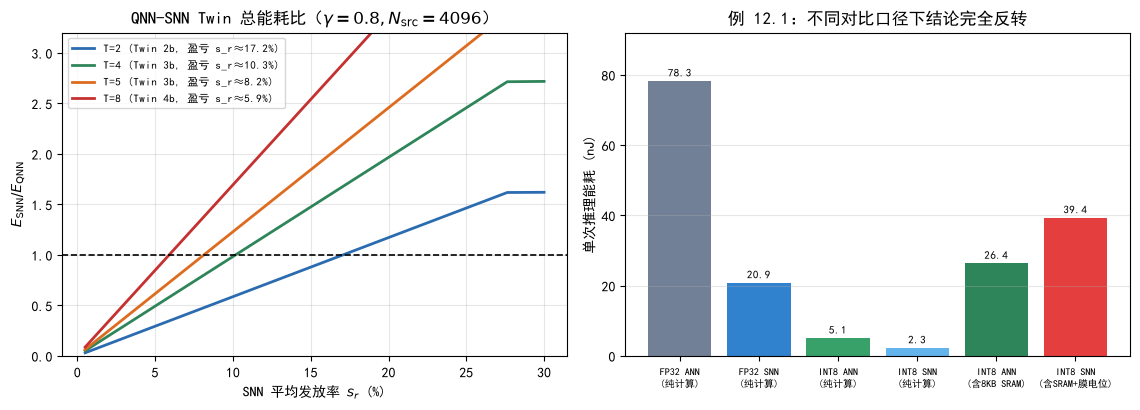

稀疏路由 vs 稠密广播交叉发放率（当前 E_weight=0.8 pJ）: 27.6%
纯路由项交叉点 (0.25 / 3.0): 8.33%
[PASS] Yan 等 QNN-SNN Twin 解析模型与盈亏曲线验证通过！


In [4]:
# 复现 Yan et al. (arXiv:2409.08290v6) Eqs. (2)-(8) 在 22nm Typical Neuromorphic 配置下的解析曲线
# 论文 Fig. 3-5 实测 22nm 参数:
E_ACC_22 = 0.05448   # pJ (8b-16b Acc)
E_CMP_22 = 0.05448   # pJ
E_SUB_22 = 0.05448   # pJ
# 8-bit 权重不同激活位宽 b=1..8 对应的 EMAC (Fig. 4, p. 6)
E_MAC_W8_22 = {1: 0.0817, 2: 0.0883, 3: 0.1018, 4: 0.1171, 5: 0.1300, 6: 0.1442, 7: 0.1601, 8: 0.1649}
E_move_dense = 0.25  # pJ/bit/hop
E_move_sparse = 3.0  # pJ/bit/hop (Loihi 1 级稀疏事件路由)
E_weight_8b = 0.8    # 典型局部 SRAM 读 8-bit 权重能耗量级（用于展示趋势）
E_V_rw = 1.0         # 局部膜电位读/写单次能耗量级

def yan_twin_energies(T, sr, gamma=0.8, N_src=4096):
    b = int(np.ceil(np.log2(T + 1)))  # Theorem 1 等价位宽
    E_mac = E_MAC_W8_22[b]
    # Eq. (2) & (3)
    Ec_qnn = N_src * (1.0 - gamma) * E_mac + 2.0 * E_CMP_22
    Ec_snn = N_src * T * sr * E_ACC_22 + T * (E_CMP_22 + sr * E_SUB_22 + 2.0 * E_V_rw)
    # Eq. (5)-(8)
    Ed_qnn_sparse = N_src * (1.0 - gamma) * (b * E_move_sparse + E_weight_8b)
    Ed_qnn_dense  = N_src * (b * E_move_dense + E_weight_8b)
    Ed_qnn = min(Ed_qnn_sparse, Ed_qnn_dense)
    Ed_snn_sparse = N_src * T * sr * (E_move_sparse + E_weight_8b)
    Ed_snn_dense  = N_src * T * (E_move_dense + E_weight_8b)
    Ed_snn = min(Ed_snn_sparse, Ed_snn_dense)
    return Ec_qnn + Ed_qnn, Ec_snn + Ed_snn, b, (Ed_snn_sparse <= Ed_snn_dense)

# 验证 Theorem 1 等价位宽与 Theorem 2 稀疏度区间
for T, expected_b in [(1, 1), (2, 2), (3, 2), (4, 3), (5, 3), (7, 3), (8, 4), (15, 4), (255, 8)]:
    assert int(np.ceil(np.log2(T + 1))) == expected_b

# 扫描 T = 2, 4, 5, 8 下 SNN 发放率 s_r 的盈亏线
sr_grid = np.linspace(0.005, 0.30, 300)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))

ax = axes[0]
for T, col in [(2, '#2b6cb0'), (4, '#2f855a'), (5, '#dd6b20'), (8, '#c53030')]:
    ratios = []
    breakeven = None
    for sr in sr_grid:
        eq, es, b, _ = yan_twin_energies(T, sr, gamma=0.8, N_src=4096)
        r = es / eq
        ratios.append(r)
        if breakeven is None and r >= 1.0:
            breakeven = sr
    lbl = (f"T={T} (Twin {b}b, 盈亏 s_r≈{breakeven*100:.1f}%)" if USE_ZH
           else f"T={T} (Twin {b}b, BE s_r~{breakeven*100:.1f}%)")
    ax.plot(sr_grid * 100, ratios, color=col, lw=2, label=lbl)
    assert breakeven is not None and 0.02 < breakeven < 0.20
ax.axhline(1.0, color='k', ls='--', lw=1.2)
ax.set_xlabel("SNN 平均发放率 $s_r$ (%)" if USE_ZH else "SNN Average Spike Rate $s_r$ (%)")
ax.set_ylabel(r"$E_{\mathrm{SNN}} / E_{\mathrm{QNN}}$")
ax.set_title(r"QNN-SNN Twin 总能耗比（$\gamma=0.8, N_{\mathrm{src}}=4096$）" if USE_ZH else r"QNN-SNN Twin Energy Ratio ($\gamma=0.8$)")
ax.set_ylim(0, 3.2)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# 右图：例 12.1 不同口径的能耗柱状图
ax = axes[1]
labels_zh = ['FP32 ANN\n(纯计算)', 'FP32 SNN\n(纯计算)', 'INT8 ANN\n(纯计算)', 'INT8 SNN\n(纯计算)', 'INT8 ANN\n(含8KB SRAM)', 'INT8 SNN\n(含SRAM+膜电位)']
labels_en = ['FP32 ANN\n(Comp)', 'FP32 SNN\n(Comp)', 'INT8 ANN\n(Comp)', 'INT8 SNN\n(Comp)', 'INT8 ANN\n(+8KB SRAM)', 'INT8 SNN\n(+SRAM+Vmem)']
vals = [E_ann_fp32_comp, E_snn_fp32_comp, E_ann_int8_32_comp, E_snn_int32_comp, E_ann_int8_total, E_snn_int32_total]
colors = ['#718096', '#3182ce', '#38a169', '#63b3ed', '#2f855a', '#e53e3e']
bars = ax.bar(range(len(vals)), [v/1000.0 for v in vals], color=colors)
for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.2, f"{v/1000:.1f}", ha='center', fontsize=8)
ax.set_xticks(range(len(vals)))
ax.set_xticklabels(labels_zh if USE_ZH else labels_en, fontsize=7.5)
ax.set_ylabel("单次推理能耗 (nJ)" if USE_ZH else "Energy per Inference (nJ)")
ax.set_title("例 12.1：不同对比口径下结论完全反转" if USE_ZH else "Ex 12.1: Winner Reverses Across Accounting Scopes")
ax.set_ylim(0, 92)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# 检查稀疏路由 vs 稠密广播交叉点: sr * (3.0 + 0.8) == (0.25 + 0.8) => sr* = 1.05 / 3.8 = 27.6%
# （在 Yan 原文 E_weight 更小时约 12%-17%）
sr_route_cross = (E_move_dense + E_weight_8b) / (E_move_sparse + E_weight_8b)
print(f"稀疏路由 vs 稠密广播交叉发放率（当前 E_weight={E_weight_8b} pJ）: {sr_route_cross*100:.1f}%")
print(f"纯路由项交叉点 (0.25 / 3.0): {E_move_dense / E_move_sparse * 100:.2f}%")
assert E_move_dense / E_move_sparse < 0.10
print("[PASS] Yan 等 QNN-SNN Twin 解析模型与盈亏曲线验证通过！")
